# **DATA INTENSIVE SYSTEMS IN BIOMEDICINE**

**Autorzy:**
* Jakub Grobelny (252849)
* Ziemowit Karbownik (251264)
* Zuzanna Rykaczewska (251275)

---

## **Spis treści**
1. [Wprowadzenie i opis projektu](#1-wprowadzenie-i-opis-projektu)
2. [Wczytanie danych i analiza struktury zbioru](#2-wczytanie-danych-i-analiza-struktury-zbioru)
3. [Analiza jakości i czyszczenie danych](#3-analiza-jakości-i-czyszczenie-danych)
4. [Analiza eksploracyjna danych](#4-analiza-eksploracyjna-danych)
5. [Przetwarzanie danych w paradygmacie MapReduce z użyciem funkcji lambda](#5-mapreduce---analiza-wskaznika-cukrzycy-per-cecha)
6. [Przygotowanie danych do predykcji i klasyfikacja](#6-przygotowanie-danych-do-predykcji-i-klasyfikacja)
7. [Budowa i trenieng modeli](#7-budowa-i-trening-modeli)
8. [Ewaluacja i analiza porównawcza modeli](#8-ewaluacja-i-analiza-porównawcza-modeli)
9. [Wnioski](#9-wnioski)


---

## **1. Wprowadzenie i opis projektu**

### **Wprowadzenie:**

Cukrzyca to przewlekła, metaboliczna choroba cywilizacyjna, charakteryzująca się przewlekłą hiperglikemią. Wynika ona z zaburzeń w wydzielaniu lub działaniu insuliny. Wczesna identyfikacja czynników ryzyka (takich jak wskaźnik BMI, nadciśnienie tętnicze, wiek czy ogólny stan zdrowia) przy użyciu metod zautomatyzowanych pozwala na szybkie wdrożenie działań profilaktycznych, co stanowi kluczowy element współczesnej telemedycyny i systemów wspomagania decyzji medycznych.

### **Opis projektu:**

Celem projektu jest przeprowadzenie kompleksowej analizy zbioru danych dotyczącego wskaźników zdrowotnych powiązanych z ryzykiem zachorowania na cukrzycę. Projekt został zrealizowany w oparciu o architekturę Apache Spark, co zapewnia wysoką wydajność obliczeniową oraz skalowalność przetwarzania danych.

---

## **2. Wczytanie danych i analiza struktury zbioru**
### 2.1 Wczytanie danych za pomocą Apache Spark i wyświetlenie 10 pierwszych wierszy

In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Diabetes Analysis") \
    .getOrCreate()

DATA_PATH = "/app/data/diabetes_health_indicators.csv"

df = spark.read.csv(
    DATA_PATH,
    header=True,
    inferSchema=True
)

df.show(10, truncate=False)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/06/19 20:45:38 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


+------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|Diabetes_012|HighBP|HighChol|CholCheck|BMI |Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex|Age |Education|Income|
+------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|0.0         |1.0   |1.0     |1.0      |40.0|1.0   |0.0   |0.0                 |0.0         |0.0   |1.0    |0.0              |1.0          |0.0        |5.0    |18.0    |15.0    |1.0     |0.0|9.0 |4.0      |3.0   |
|0.0         |0.0   |0.0     |0.0      |25.0|1.0   |0.0   |0.0                 |1.0         |0.0   |0.0    |0.0              |0.0          |1.0 

### 2.2 Analiza struktury zbioru

In [2]:
print("-" * 15 + "Informacje o Strukturze bazy danych" + "-" * 15)
print(f'Całkowita ilość wierszy: {df.count()}')
print(f'Całkowita ilość kolumn: {len(df.columns)}')
print(65 * "-")

---------------Informacje o Strukturze bazy danych---------------
Całkowita ilość wierszy: 253680
Całkowita ilość kolumn: 22
-----------------------------------------------------------------


In [3]:
df.printSchema()

root
 |-- Diabetes_012: double (nullable = true)
 |-- HighBP: double (nullable = true)
 |-- HighChol: double (nullable = true)
 |-- CholCheck: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Smoker: double (nullable = true)
 |-- Stroke: double (nullable = true)
 |-- HeartDiseaseorAttack: double (nullable = true)
 |-- PhysActivity: double (nullable = true)
 |-- Fruits: double (nullable = true)
 |-- Veggies: double (nullable = true)
 |-- HvyAlcoholConsump: double (nullable = true)
 |-- AnyHealthcare: double (nullable = true)
 |-- NoDocbcCost: double (nullable = true)
 |-- GenHlth: double (nullable = true)
 |-- MentHlth: double (nullable = true)
 |-- PhysHlth: double (nullable = true)
 |-- DiffWalk: double (nullable = true)
 |-- Sex: double (nullable = true)
 |-- Age: double (nullable = true)
 |-- Education: double (nullable = true)
 |-- Income: double (nullable = true)



### **Opis struktury danych**

Dzięki zastosowaniu funkcji `printSchema()` możliwe jest wyświetlenie struktury bazy danych. Analizując wynik można zauważyć, że:
- Wszystkie kolumny w zbiorze danych są typu numerycznego (`double`),
- Każda kolumna dopuszcza wartości NULL (nullable = true), jednak wcześniejsza analiza wykazała brak takich danych.

In [4]:
df.describe().show(truncate=False)

26/06/19 20:45:48 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-------------------+-------------------+-------------------+------------------+------------------+-------------------+-------------------+--------------------+------------------+-------------------+-------------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+-------------------+------------------+------------------+------------------+------------------+
|summary|Diabetes_012       |HighBP             |HighChol           |CholCheck         |BMI               |Smoker             |Stroke             |HeartDiseaseorAttack|PhysActivity      |Fruits             |Veggies            |HvyAlcoholConsump  |AnyHealthcare      |NoDocbcCost        |GenHlth           |MentHlth          |PhysHlth          |DiffWalk           |Sex               |Age               |Education         |Income            |
+-------+-------------------+-------------------+-------------------+------------------+------------------+-----------

### 2.3 Podział zmiennych

Na podstawie analizy zbioru danych można wyróżnić kilka typów zmiennych, które się w nim znajdują:

| Typ zmiennej | Nazwa zmiennej | Opis | Wartości / Zakres |
| :--- | :--- | :--- | :--- |
| **Docelowa** | `Diabetes_012` | Status cukrzycy | 0 – brak, 1 – stan przedcukrzycowy, 2 – cukrzyca |
| **Binarna** | `HighBP` | Nadciśnienie | 0 – brak, 1 – występuje |
| **Binarna** | `HighChol` | Wysoki cholesterol | 0 – brak, 1 – występuje |
| **Binarna** | `CholCheck` | Badanie cholesterolu w ciągu ostatnich 5 lat | 0 – brak, 1 – tak |
| **Binarna** | `Smoker` | Czy kiedykolwiek wypalono ≥100 papierosów | 0 – nie, 1 – tak |
| **Binarna** | `Stroke` | Przebyty udar | 0 – nie, 1 – tak |
| **Binarna** | `HeartDiseaseorAttack` | Choroba serca lub zawał | 0 – nie, 1 – tak |
| **Binarna** | `PhysActivity` | Aktywność fizyczna w ostatnich 30 dniach | 0 – brak, 1 – tak |
| **Binarna** | `Fruits` | Spożycie owoców ≥1 raz dziennie | 0 – nie, 1 – tak |
| **Binarna** | `Veggies` | Spożycie warzyw ≥1 raz dziennie | 0 – nie, 1 – tak |
| **Binarna** | `HvyAlcoholConsump` | Nadmierne spożycie alkoholu | 0 – nie, 1 – tak |
| **Binarna** | `AnyHealthcare` | Dostęp do opieki zdrowotnej | 0 – brak, 1 – tak |
| **Binarna** | `NoDocbcCost` | Brak wizyty lekarskiej z powodu kosztów | 0 – nie, 1 – tak |
| **Binarna** | `DiffWalk` | Trudności w chodzeniu lub wchodzeniu po schodach | 0 – brak, 1 – tak |
| **Binarna** | `Sex` | Płeć | 0 – female, 1 – male |
| **Ciągła** | `BMI` | Wskaźnik masy ciała | Zakres: 12 – 98 |
| **Kategoryczna** | `GenHlth` | Ogólny stan zdrowia | 1 (excellent) do 5 (poor) |
| **Kategoryczna** | `MentHlth` | Liczba dni gorszego samopoczucia psychicznego | Zakres: 0 – 30 |
| **Kategoryczna** | `Age` | Kategoria wieku | Skala: 1 – 13 |
| **Kategoryczna** | `PhysHlth` | Liczba dni niezdrowego trybu życia | Zakres: 0 – 30 |
| **Kategoryczna** | `Education` | Poziom edukacji | 1 (brak/przedszkole) do 6 (wyższe) |
| **Kategoryczna** | `Income` | Poziom dochodu | 1 (< $10,000) do 8 (≥ $75,000) |


---
## **3. Analiza jakości i czyszczenie danych**

### 3.1 Sprawdzenie, czy występują puste wiersze

In [5]:
from pyspark.sql.functions import col, count, when

# Zliczanie brakujących (null) wartości w każdej kolumnie
missing_values = df.select([
    count(when(col(c).isNull(), c)).alias(c) 
    for c in df.columns
])

missing_values.show(truncate=False)

+------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|Diabetes_012|HighBP|HighChol|CholCheck|BMI|Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex|Age|Education|Income|
+------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|0           |0     |0       |0        |0  |0     |0     |0                   |0           |0     |0      |0                |0            |0          |0      |0       |0       |0       |0  |0  |0        |0     |
+------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-

Dla każdej kolumny sprawdzono liczbę wartości NULL. Wyniki pokazują, że żadna kolumna nie zawiera brakujących danych, ponieważ wszystkie wartości wynoszą 0 (brak braków).

W związku z tym zbiór danych nie wymagał czyszczenia. Brak brakujących danych oznacza, że dane są kompletne i mogą zostać bezpośrednio wykorzystane do dalszej analizy oraz budowy modelu ML.

---

## **4. Analiza eksploracyjna danych**

### 4.1 Badanie korelacji cech

Po przeprowadzeniu dokładnej inspekcji struktury zbioru danych wyznaczono macierz korelacji. Umożliwia to identyfikacje oraz ilościowa ocenę współzależności pomiędzy poszczególnymi kolumnami a zmienną celu(ryzykiem wystapienia cukrzycy)

26/06/19 20:45:56 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS


Text(0.5, 1.0, 'Macierz korelacji wszystkich cech')

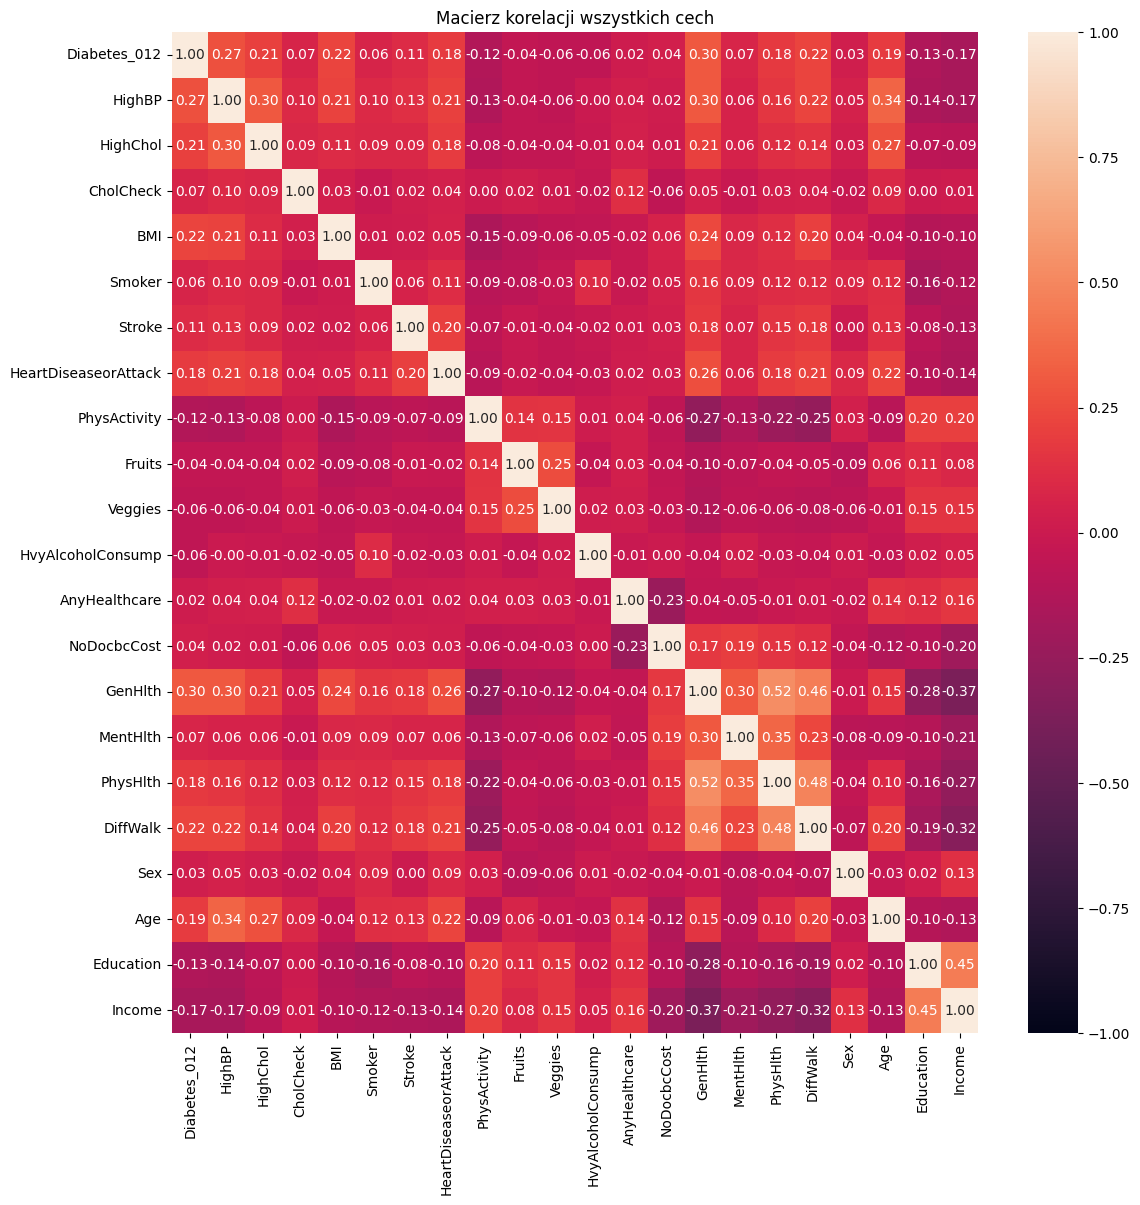

In [6]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

all_cols = df.columns

assembler = VectorAssembler(inputCols=all_cols, outputCol="features")
df_vectorized = assembler.transform(df)

matrix = Correlation.corr(df_vectorized, "features").head()[0]
corr_df = pd.DataFrame(matrix.toArray(), index=all_cols, columns=all_cols)

plt.figure(figsize=(13, 13))
sns.heatmap(corr_df, annot=True, vmin=-1, vmax=1, fmt=".2f")
plt.title("Macierz korelacji wszystkich cech")

Analiza współczynników korelacji pozwoliła na wyłonienie podzbioru cech o najwyższym potencjale predykcyjnym. Najsilniejszą, dodatnią korelację z występowaniem cukrzycy wykazują zmienne: 
* opisujące ogólny stan zdrowia pacjenta `GenHlth`: 0.30 
* wysokie ciśnienie tętnicze `HighBP`: 0.27 
* podwyższony poziom cholesterolu `HighChol`: 0.21 
* trudności z poruszaniem się `DiffWalk`: 0.22 
* wskaźnik masy ciała `BMI`: 0.22

Istotną korelację ujemną odnotowano natomiast w przypadku zmiennych ekonomiczno-społecznych, takich jak poziom dochodów `Income`: -0.17.

### 4.2 Analiza rozkładu najbardziej skorelowanych cech z zmienną celu

In [7]:
# Najbardziej interesujące cechy do analizy
FEATURE_COLS = [
    "GenHlth", "HighBP", "BMI", "Age", "HighChol", "DiffWalk",
    "HeartDiseaseorAttack", "PhysHlth", "Income", "PhysActivity",
    "Education", "Smoker"
]

categorical_features = [c for c in FEATURE_COLS if c != 'BMI'] # zmienne kategoryczne
total_count = df.count()
selected_summary_data = []

for col_name in categorical_features:
    # Pobieramy rozkład wartości dla danej kolumny ze Sparka
    counts = df.groupBy(col_name).count().orderBy(col_name).collect()
    
    for row in counts:
        val = row[col_name]
        cnt = row['count']
        percentage = (cnt / total_count) * 100
        
        selected_summary_data.append({
            "Najbardziej skorelowane cechy kategoryczne": col_name,
            "Wartość": int(val),
            "Liczba wierszy": cnt,
            "Procentowy udział": f"{percentage:.2f}%"
        })

selected_summary_df = pd.DataFrame(selected_summary_data).set_index(["Najbardziej skorelowane cechy kategoryczne", "Wartość"])
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(selected_summary_df)

Liczba wierszy  \
Najbardziej skorelowane cechy kategoryczne Wartość                   
GenHlth                                    1                 45299   
                                           2                 89084   
                                           3                 75646   
                                           4                 31570   
                                           5                 12081   
HighBP                                     0                144851   
                                           1                108829   
Age                                        1                  5700   
                                           2                  7598   
                                           3                 11123   
                                           4                 13823   
                                           5                 16157   
                                           6                 19819   
                                           7                 26314   
                                           8                 30832   
                                           9                 33244   
                                           10                32194   
                                           11                23533   
                                           12                15980   
                                           13                17363   
HighChol                                   0                146089   
                                           1                107591   
DiffWalk                                   0                211005   
                                           1                 42675   
HeartDiseaseorAttack                       0                229787   
                                           1                 23893   
PhysHlth                                   0                160052   
                                           1                 11388   
                                           2                 14764   
                                           3                  8495   
                                           4                  4542   
                                           5                  7622   
                                           6                  1330   
                                           7                  4538   
                                           8                   809   
                                           9                   179   
                                           10                 5595   
                                           11                   60   
                                           12                  578   
                                           13                   68   
                                           14                 2587   
                                           15                 4916   
                                           16                  112   
                                           17                   96   
                                           18                  152   
                                           19                   22   
                                           20                 3273   
                                           21                  663   
                                           22                   70   
                                           23                   56   
                                           24                   72   
                                           25                 1336   
                                           26                   69   
                                           27                   99   
                                           28                  522   
                                           29                 

Dla najbardziej skorelowanych cech jakościowych została również przeprowadzona wizualizacja graficzna w postaci zbiorczych wykresów częstości. Działanie to ma na celu czytelne zobrazowanie dysproporcji oraz struktur rozkładów wewnątrz wyselekcjonowanych grup zmiennych. Analiza wizualna pozwala na natychmiastową ocenę stopnia zrównoważenia poszczególnych klas, co jest istotne z punktu widzenia interpretacji zachowania algorytmów uczenia maszynowego oraz poprawnego zrozumienia profilu zdrowotnego badanej populacji pacjentów.

/tmp/ipykernel_1077/3240320007.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=pdf, x=col_name, ax=axes[i], palette="Blues_r", edgecolor="black", linewidth=0.7)
/tmp/ipykernel_1077/3240320007.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=pdf, x=col_name, ax=axes[i], palette="Blues_r", edgecolor="black", linewidth=0.7)
/tmp/ipykernel_1077/3240320007.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=pdf, x=col_name, ax=axes[i], palette="Blues_r", edgecolor="black", linewidth=0.7)
/tmp/ipykernel_1077/32403200

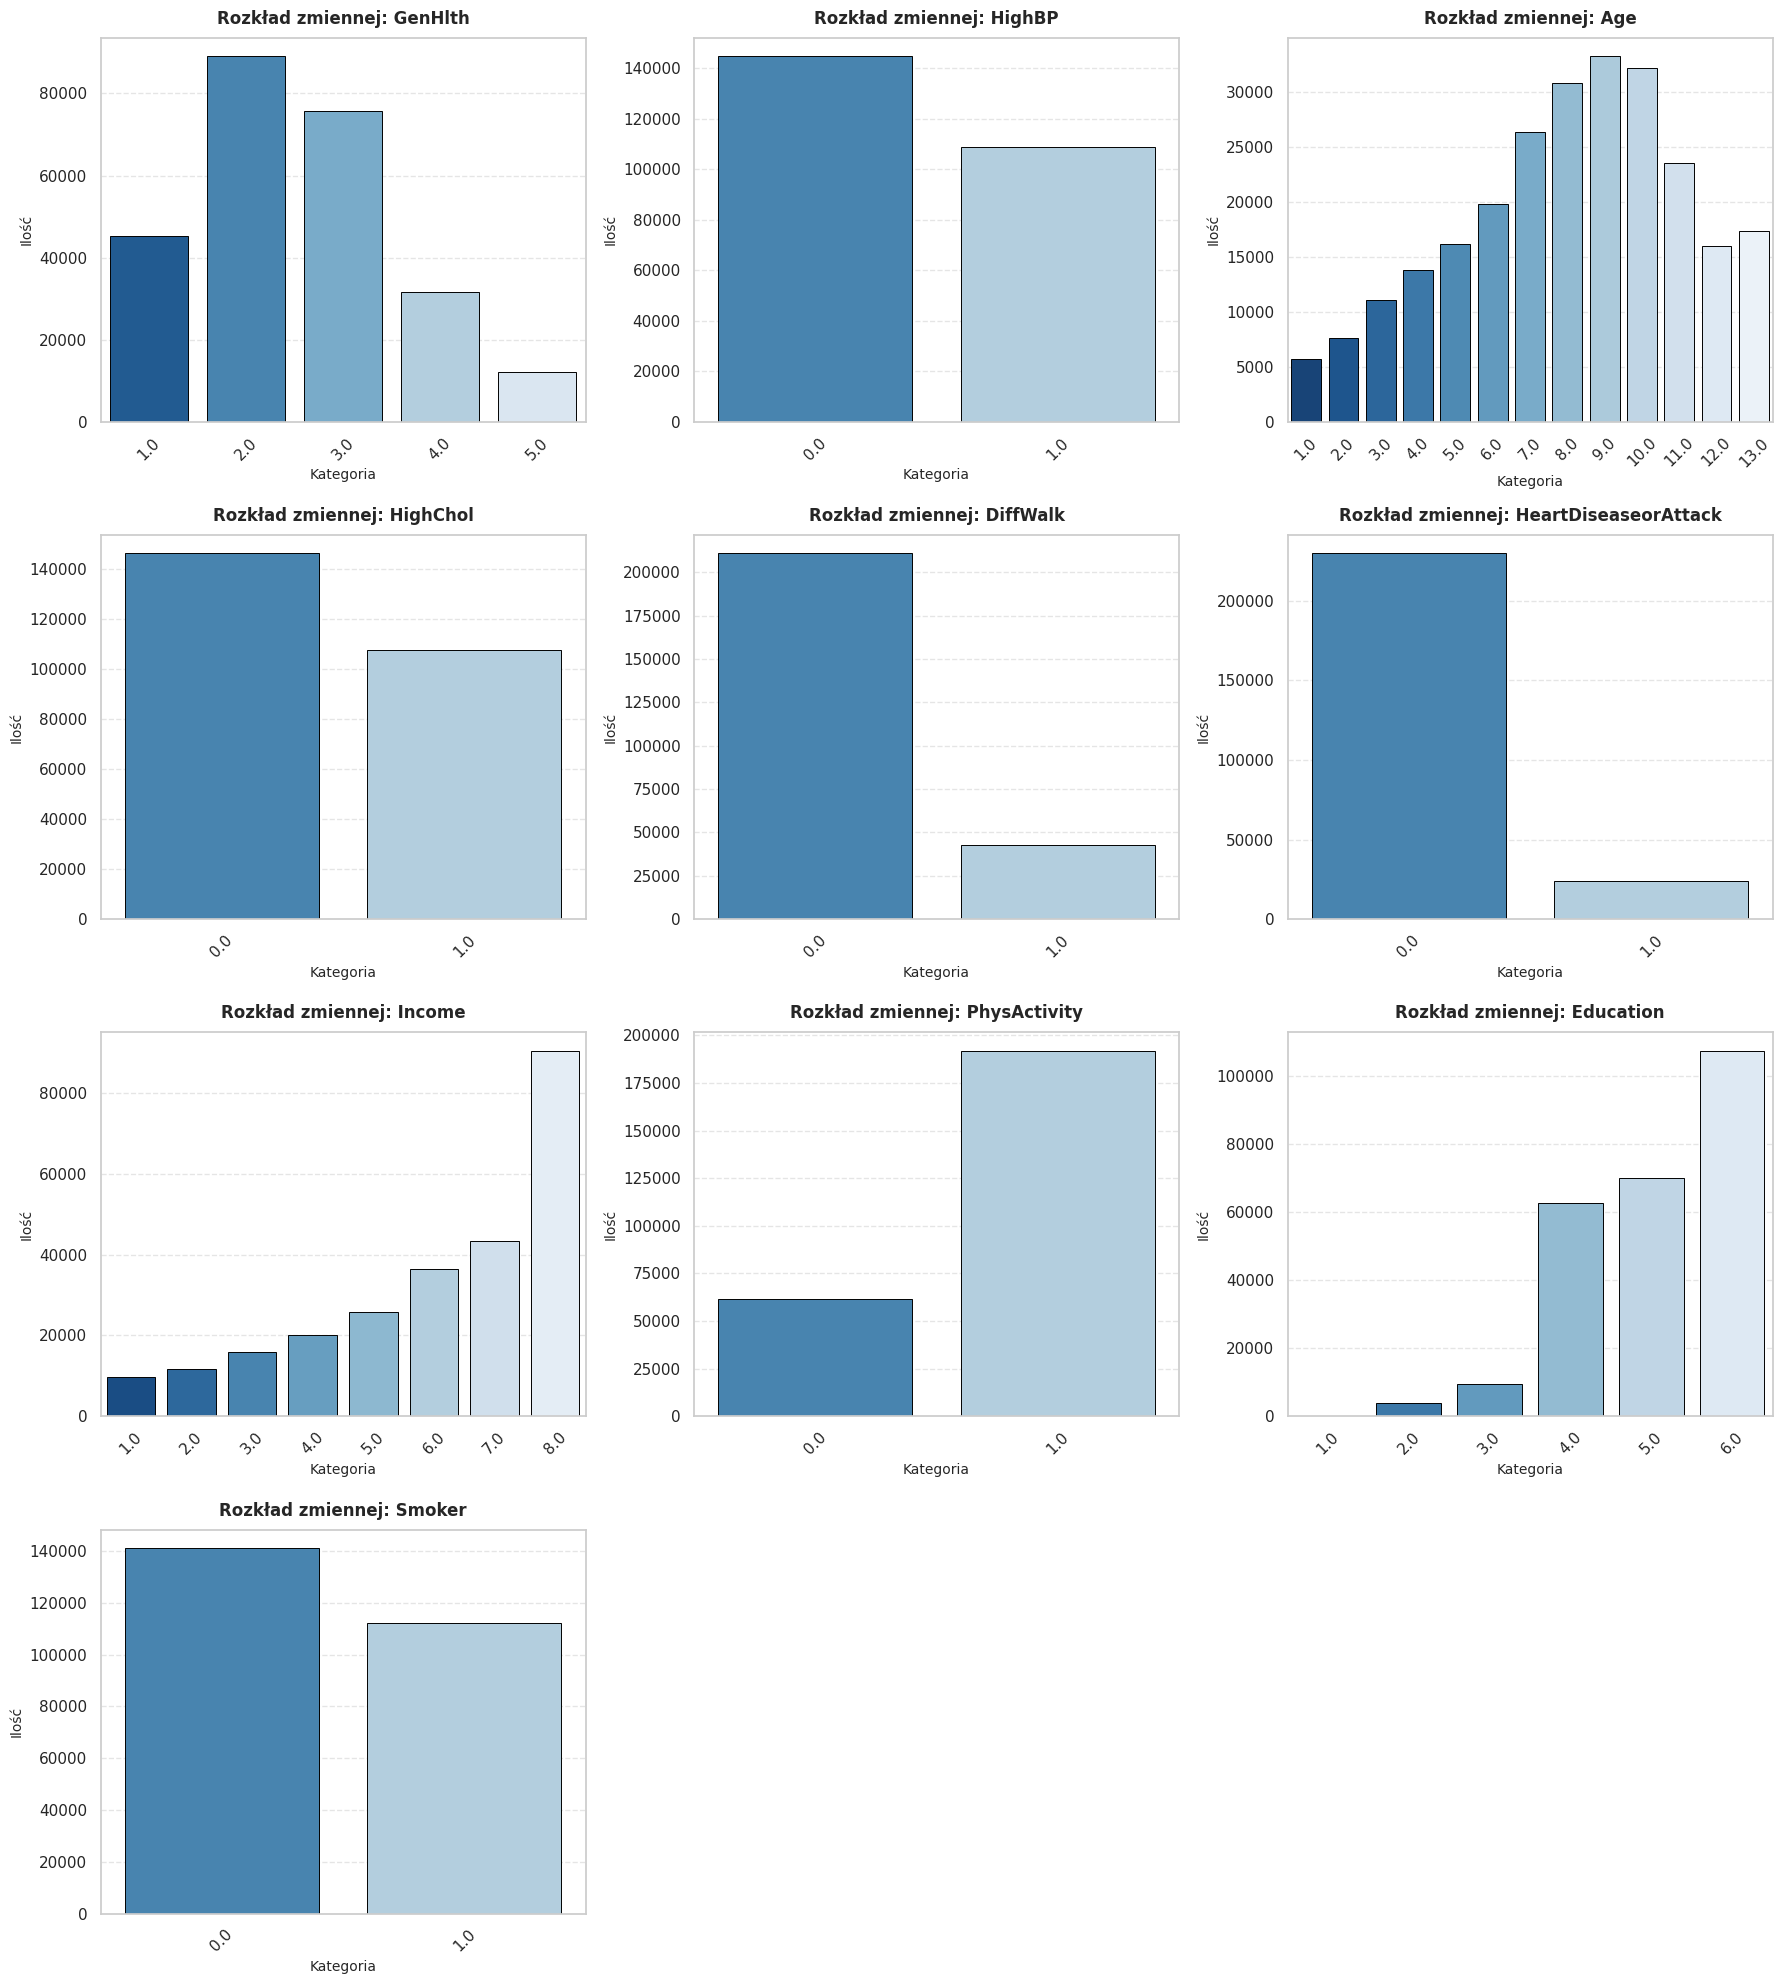

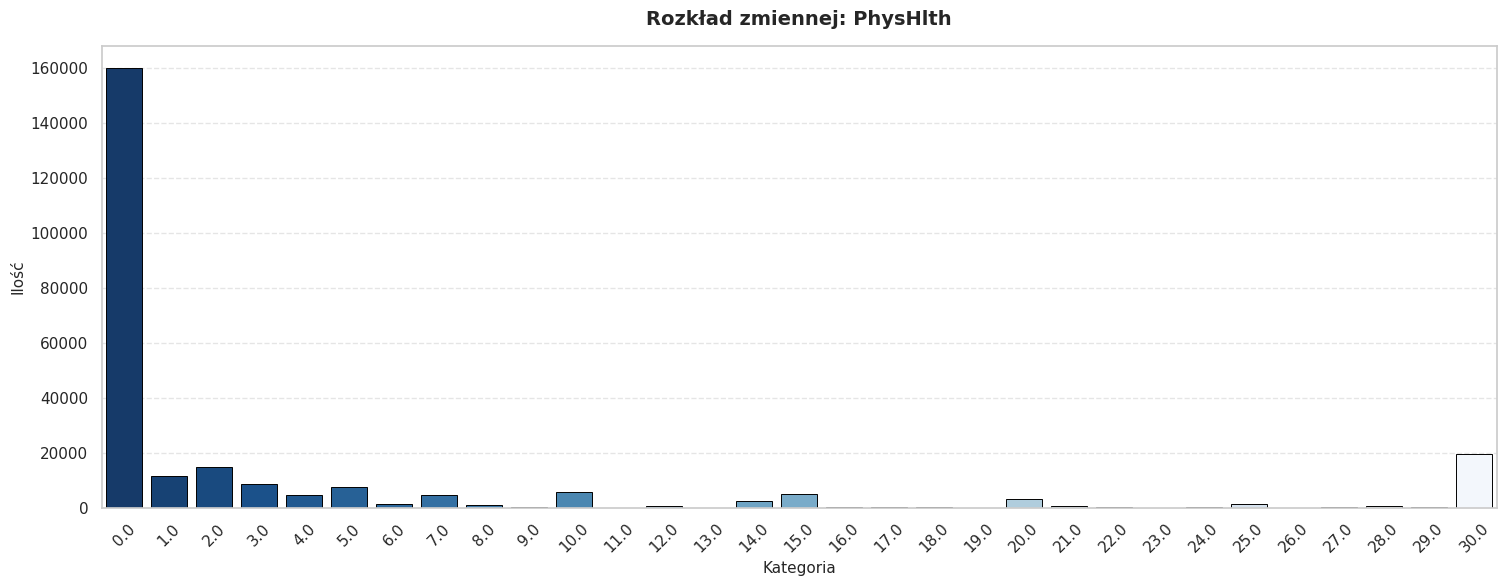

In [8]:
import math

features_to_grid = [c for c in categorical_features if c != "PhysHlth"]
n_cols = 3
n_rows = math.ceil(len(features_to_grid) / n_cols)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, col_name in enumerate(features_to_grid):
    pdf = df.select(col_name).toPandas()
    sns.countplot(data=pdf, x=col_name, ax=axes[i], palette="Blues_r", edgecolor="black", linewidth=0.7)
    
    axes[i].set_title(f"Rozkład zmiennej: {col_name}", fontsize=12, fontweight='bold', pad=10)
    axes[i].set_xlabel("Kategoria", fontsize=10)
    axes[i].set_ylabel("Ilość", fontsize=10)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()


pdf_phys = df.select("PhysHlth").toPandas()
plt.figure(figsize=(18, 6))
ax = sns.countplot(data=pdf_phys, x="PhysHlth", palette="Blues_r", edgecolor="black", linewidth=0.7)
plt.title("Rozkład zmiennej: PhysHlth", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Kategoria", fontsize=11)
plt.ylabel("Ilość", fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

Dla cechy ilościowej BMI stworzono histogram z rozkładem gęstości oraz wykres pudełkowy. Pozwala to na precyzyjną ocenę asymetrii rozkładu, wyznaczenie średniej i mediany oraz identyfikację odstających wartości.

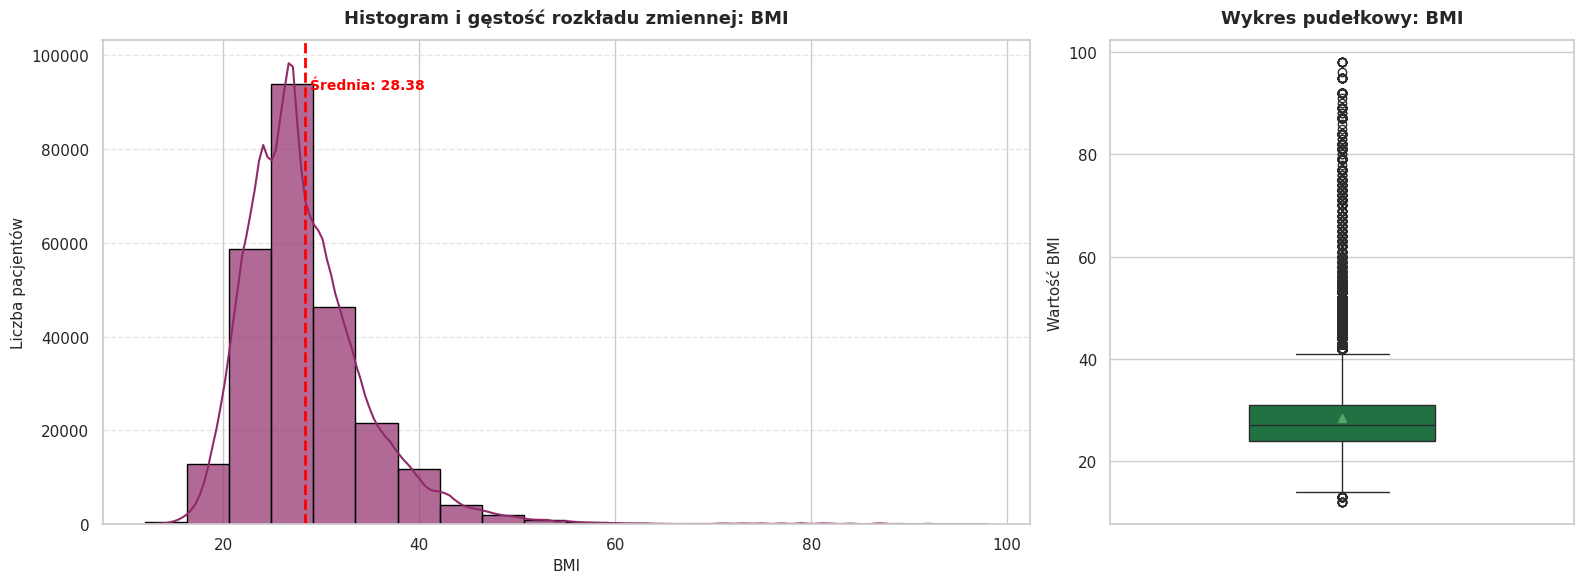

In [9]:
pdf_bmi = df.select("BMI").toPandas()
bmi_mean = pdf_bmi["BMI"].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [2, 1]})

sns.histplot(data=pdf_bmi, x="BMI", bins=20, kde=True, color="#8f2b69", edgecolor="black", alpha=0.7, ax=axes[0])
axes[0].axvline(bmi_mean, color="red", linestyle="--", linewidth=2, label=f"Średnia: {bmi_mean:.2f}")
ymin, ymax = axes[0].get_ylim()
axes[0].text(bmi_mean + 0.5, ymax * 0.9, f"Średnia: {bmi_mean:.2f}", color="red", fontweight="bold", fontsize=10)
axes[0].set_title("Histogram i gęstość rozkładu zmiennej: BMI", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("BMI", fontsize=11)
axes[0].set_ylabel("Liczba pacjentów", fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

sns.boxplot(data=pdf_bmi, y="BMI", color="#148041", width=0.4,showmeans=True, ax=axes[1])
axes[1].set_title("Wykres pudełkowy: BMI", fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel("Wartość BMI", fontsize=11)

plt.tight_layout()

---

## **5. MapReduce - analiza wskaznika cukrzycy per cecha**

### Binaryzacja zmiennej docelowej

Zmienna `Diabetes_012` przyjmuje wartości 0 (brak), 1 (stan przedcukrzycowy) i 2 (cukrzyca). Ze względu na silną **nierównowagę klas** (klasa 1 to zaledwie ~1.8% danych), przekształcamy problem do klasyfikacji binarnej:
- `0` → brak cukrzycy
- `1` → cukrzyca lub stan przedcukrzycowy (klasy 1 i 2 łącznie)

Do transformacji używamy **funkcji lambda** oraz paradygmatu **MapReduce**.

In [10]:
from pyspark.sql.functions import col, udf
from pyspark.sql.types import IntegerType

# Lambda: 0 -> 0 (zdrowy), 1 lub 2 -> 1 (chory/zagrozony)
binarize = udf(lambda x: 0 if x == 0.0 else 1, IntegerType())

df_binary = df.withColumn("label", binarize(col("Diabetes_012")))

print("Rozklad zmiennej label (0 = brak, 1 = cukrzyca/przedcukrzycowy):")
df_binary.groupBy("label").count().orderBy("label").show()

total = df_binary.count()
counts = {row["label"]: row["count"] for row in df_binary.groupBy("label").count().collect()}
for label, cnt in sorted(counts.items()):
    print(f"  Klasa {label}: {cnt} ({cnt/total*100:.1f}%)")

Rozklad zmiennej label (0 = brak, 1 = cukrzyca/przedcukrzycowy):


+-----+------+
|label| count|
+-----+------+
|    0|213703|
|    1| 39977|
+-----+------+

  Klasa 0: 213703 (84.2%)
  Klasa 1: 39977 (15.8%)


Przy użyciu paradygmatu MapReduce obliczamy odsetek chorych dla każdej wartości wybranych cech binarnych. Każdy wiersz jest mapowany na parę `(wartosc_cechy, label)`, a nastepnie redukowany do średniego wskaźnika cukrzycy.

In [11]:
# MapReduce: odsetek chorych per wartosc cechy binarnej
binary_features = ["HighBP", "HighChol", "Smoker", "Stroke",
                   "HeartDiseaseorAttack", "PhysActivity", "DiffWalk"]

print(f"{'Cecha':<25} {'Wartosc':<10} {'Lącznie':<10} {'Chorych':<10} {'Odsetek %':<10}")
print("-" * 65)

for feature in binary_features:
    rdd_mapped = df_binary.select(feature, "label").rdd \
        .map(lambda row: ((row[0], row[1]), 1))

    rdd_reduced = rdd_mapped.reduceByKey(lambda a, b: a + b)

    result = rdd_reduced.collect()

    totals = {}
    sick = {}
    for (val, lbl), cnt in result:
        totals[val] = totals.get(val, 0) + cnt
        if lbl == 1:
            sick[val] = sick.get(val, 0) + cnt

    for val in sorted(totals.keys()):
        s = sick.get(val, 0)
        pct = s / totals[val] * 100
        print(f"{feature:<25} {val:<10.0f} {totals[val]:<10} {s:<10} {pct:<10.1f}")
print()

Cecha                     Wartosc    Lącznie    Chorych    Odsetek % 
-----------------------------------------------------------------


HighBP                    0          144851     10460      7.2       
HighBP                    1          108829     29517      27.1      
HighChol                  0          146089     13416      9.2       
HighChol                  1          107591     26561      24.7      
Smoker                    0          141257     19378      13.7      
Smoker                    1          112423     20599      18.3      
Stroke                    0          243388     36444      15.0      
Stroke                    1          10292      3533       34.3      


HeartDiseaseorAttack      0          229787     31435      13.7      
HeartDiseaseorAttack      1          23893      8542       35.8      
PhysActivity              0          61760      14548      23.6      
PhysActivity              1          191920     25429      13.2      
DiffWalk                  0          211005     25571      12.1      
DiffWalk                  1          42675      14406      33.8      



---

## **6. Przygotowanie danych do predykcji i klasyfikacja**

Na podstawie przeprowadzonej wcześniej analizy eksploracyjnej oraz weryfikacji macierzy współczynników korelacji do etapu modelowania predykcyjnego wykorzystano wcześniej wyselekcjonowany podzbiór cech posiadający największą korelacje z binarną zmienną celu. Odrzucenie zmiennych o niewielkim wpływie pozwala na redukcję szumu informacyjnego oraz optymalizację wymiarowości przestrzeni cech.

Dostępny zbiór danych został losowo podzielony na podzbiór treningowy oraz testowy w stosunku 80% do 20%., co pozwoli na niezależną ocenę zdolności generalizacyjnych modeli.

Poniewaz klasy są niezrównoważone (klasa 0: ~84%, klasa 1: ~16%), do zbioru treningowego dodano wagi klas obliczone jako:

```
waga = total / (n_klas * liczba_probek_w_klasie)
```

Dzięki takiemu działaniu model nie bedzie ignorował mniejszościowej klasy chorych.

In [12]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml import Pipeline
from pyspark.sql.functions import lit
from pyspark.sql.functions import udf as spark_udf
from pyspark.sql.types import DoubleType

assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="features",
                        withStd=True, withMean=False)

df_ml = df_binary.select(FEATURE_COLS + ["label"])

train_df, test_df = df_ml.randomSplit([0.8, 0.2], seed=42)

# Obliczenie wag klas
counts = {row["label"]: row["count"] for row in train_df.groupBy("label").count().collect()}
total_train = sum(counts.values())
n_classes = len(counts)
class_weights = {label: total_train / (n_classes * cnt) for label, cnt in counts.items()}

print(f"Zbior treningowy: {total_train} wierszy (80.00%)")
print(f"Zbior testowy:    {test_df.count()} wierszy (20.00%)")
print(f"Wagi klas: {class_weights}")

weight_map = class_weights
weight_udf = spark_udf(lambda label: float(weight_map[label]), DoubleType())
train_weighted = train_df.withColumn("classWeight", weight_udf("label"))
print("\nDodano kolumne classWeight do zbioru treningowego.")

Zbior treningowy: 203083 wierszy (80.00%)
Zbior testowy:    50597 wierszy (20.00%)
Wagi klas: {1: 3.1898187415575032, 0: 0.5929430656934307}

Dodano kolumne classWeight do zbioru treningowego.


---

## **7. Budowa i trening modeli**

W celu dokonania predykcji ryzyka cukrzycy wykorzystano dwa zróżnicowane podejścia:
- model bazowy w postaci regresji logistycznej 
- XGBoost

Uzyskane wyniki zostaną porównane na podstawie wyznaczonych metryk jakości, co pozwoli na jednoznaczne określenie, które z rozwiązań cechuje się wyższą efektywnością predykcyjną w przypadku wykrywania cukrzycy.

### **Model 1: Regresja logistyczna**

Regresja logistyczna stanowi punkt odniesienia. Jest interpretowalna i szybka w trenowaniu.

In [13]:
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

lr = LogisticRegression(featuresCol="features", labelCol="label",
                        weightCol="classWeight",
                        maxIter=100, regParam=0.01, elasticNetParam=0.0)

pipeline_lr = Pipeline(stages=[assembler, scaler, lr])
model_lr = pipeline_lr.fit(train_weighted)
pred_lr = model_lr.transform(test_df)

eval_binary = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction")
eval_multi  = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

auc_lr  = eval_binary.evaluate(pred_lr, {eval_binary.metricName: "areaUnderROC"})
acc_lr  = eval_multi.evaluate(pred_lr,  {eval_multi.metricName: "accuracy"})
f1_lr   = eval_multi.evaluate(pred_lr,  {eval_multi.metricName: "f1"})
prec_lr = eval_multi.evaluate(pred_lr,  {eval_multi.metricName: "weightedPrecision"})
rec_lr  = eval_multi.evaluate(pred_lr,  {eval_multi.metricName: "weightedRecall"})

### **Model 2: XGBoost**

XGBoost to zaawansowany algorytm ansamblowy oparty na sekwencyjnym wzmacnianiu gradientowym drzew decyzyjnych. Cechuje się wyjątkową wydajnością obliczeniową w środowiskach rozproszonych, natywną regularyzacją zapobiegającą przeuczeniu oraz znakomitą skutecznością w wychwytywaniu złożonych, nieliniowych zależności między cechami. Podobnie jak Random Forest, umożliwia także precyzyjne wyznaczenie rankingu ważności cech (*Feature Importance*).

In [14]:
from xgboost.spark import SparkXGBClassifier
from pyspark.ml import Pipeline

xgb = SparkXGBClassifier(
    features_col="features",
    label_col="label",
    weight_col="classWeight",
    num_workers=2,

    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,

    n_estimators=200,
    learning_rate=0.05,

    reg_alpha=0.1,
    reg_lambda=1.0,
    verbosity=1,

    verbose_eval=False,
)

pipeline_xgb = Pipeline(stages=[assembler, scaler, xgb])

model_xgb = pipeline_xgb.fit(train_weighted)

pred_xgb = model_xgb.transform(test_df)

auc_xgb  = eval_binary.evaluate(pred_xgb, {eval_binary.metricName: "areaUnderROC"})
acc_xgb  = eval_multi.evaluate(pred_xgb,  {eval_multi.metricName: "accuracy"})
f1_xgb   = eval_multi.evaluate(pred_xgb,  {eval_multi.metricName: "f1"})
prec_xgb = eval_multi.evaluate(pred_xgb,  {eval_multi.metricName: "weightedPrecision"})
rec_xgb  = eval_multi.evaluate(pred_xgb,  {eval_multi.metricName: "weightedRecall"})

2026-06-19 20:46:45,909 INFO XGBoost-PySpark: _fit Running xgboost-3.2.0 on 2 workers with
	booster params: {'objective': 'binary:logistic', 'colsample_bytree': 0.8, 'device': 'cpu', 'learning_rate': 0.05, 'max_depth': 5, 'min_child_weight': 3, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'subsample': 0.8, 'verbosity': 1, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 200}
	dmatrix_kwargs: {'nthread': 1, 'missing': nan}
2026-06-19 20:46:49,927 INFO XGBoost-PySpark: _train_booster Training on CPUs 2]
[20:46:51] Task 1 got rank 1[20:46:51] Task 0 got rank 0

[20:46:51] [0]	training-logloss:0.67952
[20:46:51] [1]	training-logloss:0.66763
[20:46:51] [2]	training-logloss:0.65676
[20:46:51] [3]	training-logloss:0.64652
[20:46:51] [4]	training-logloss:0.63883
[20:46:51] [5]	training-logloss:0.63014
[20:46:51] [6]	training-logloss:0.62298
[20:46:51] [7]	training-logloss:0.61540
[20:46:51] [8]	training-logloss:0.60868
[20:46:51] [9]	training-logloss:0.60242
[20:46:51

---

## **8. Ewaluacja i analiza porównawcza modeli**

Analiza porównawcza parametrów jakościowych obydwu klasyfikatorów wraz z wizualizacją metryk.

                     AUC-ROC  Accuracy  F1-score  Precision  Recall
Model                                                              
Logistic Regression   0.8137    0.7294    0.7625     0.8441  0.7294
XGBoost               0.8223    0.7211    0.7562     0.8479  0.7211


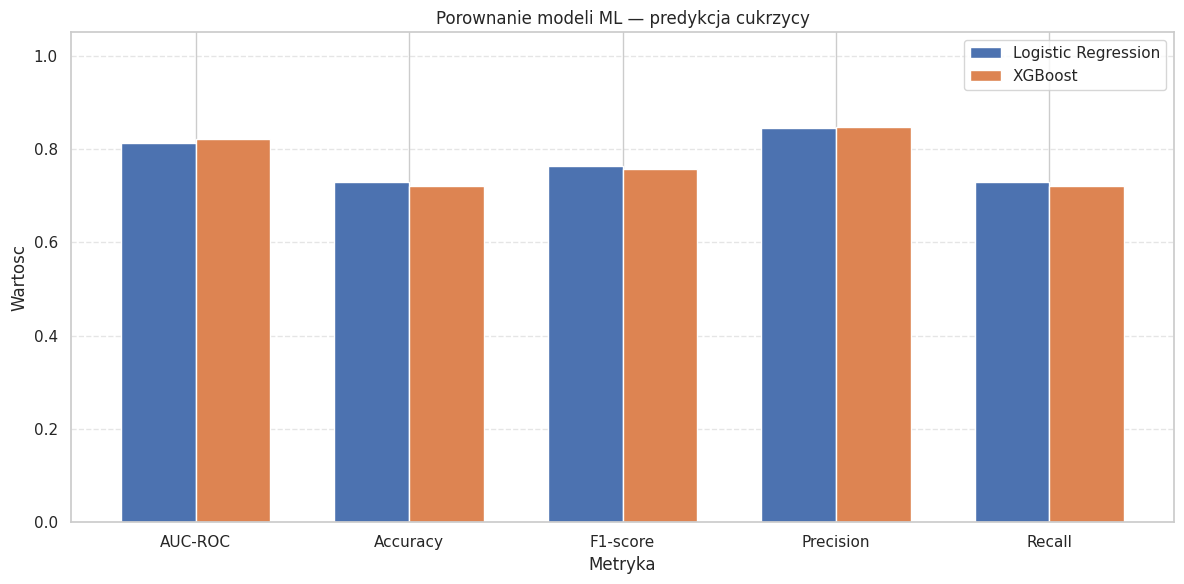

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results = {
    "Model":     ["Logistic Regression", "XGBoost"],
    "AUC-ROC":   [auc_lr,  auc_xgb],
    "Accuracy":  [acc_lr,  acc_xgb],
    "F1-score":  [f1_lr,   f1_xgb],
    "Precision": [prec_lr, prec_xgb],
    "Recall":    [rec_lr,  rec_xgb],
}

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4).to_string())

metrics = ["AUC-ROC", "Accuracy", "F1-score", "Precision", "Recall"]
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
for i, model in enumerate(results_df.index):
    vals = [results_df.loc[model, m] for m in metrics]
    ax.bar(x + i * width, vals, width, label=model)

ax.set_xlabel("Metryka")
ax.set_ylabel("Wartosc")
ax.set_title("Porownanie modeli ML — predykcja cukrzycy")
ax.set_xticks(x + width / 2)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### **Macierz pomyłek**

Macierz pomyłek pokazuje jak model klasyfikuje poszczególne przypadki. Budujemy ją ręcznie przy użyciu MapReduce.

2026-06-19 20:47:05,620 INFO XGBoost-PySpark: predict_udf Do the inference on the CPUs


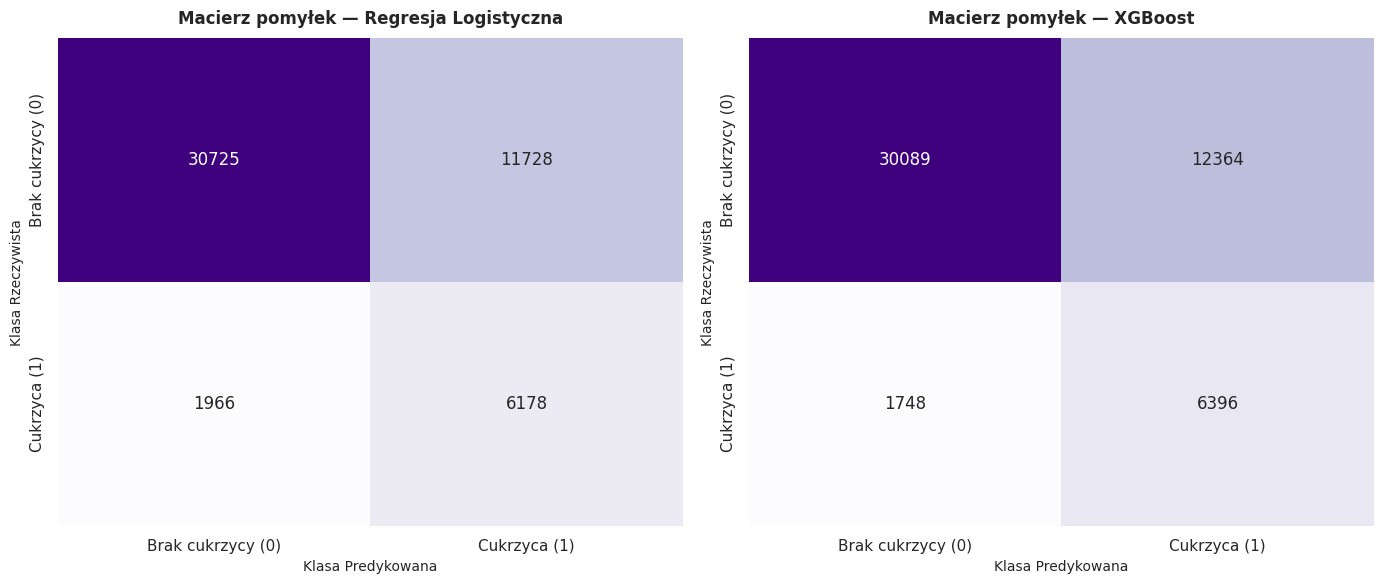

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_true_lr = pred_lr.select("label").toPandas()
y_pred_lr = pred_lr.select("prediction").toPandas()
cm_lr = confusion_matrix(y_true_lr, y_pred_lr)

y_true_xgb = pred_xgb.select("label").toPandas()
y_pred_xgb = pred_xgb.select("prediction").toPandas()
cm_xgb = confusion_matrix(y_true_xgb, y_pred_xgb)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
labels = ['Brak cukrzycy (0)', 'Cukrzyca (1)']

sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Purples', cbar=False, ax=axes[0],
            xticklabels=labels, yticklabels=labels)
axes[0].set_title('Macierz pomyłek — Regresja Logistyczna', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Klasa Predykowana', fontsize=10)
axes[0].set_ylabel('Klasa Rzeczywista', fontsize=10)

sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Purples', cbar=False, ax=axes[1],
            xticklabels=labels, yticklabels=labels)
axes[1].set_title('Macierz pomyłek — XGBoost', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Klasa Predykowana', fontsize=10)
axes[1].set_ylabel('Klasa Rzeczywista', fontsize=10)

plt.tight_layout()
plt.show()

### **Krzywa ROC**

Krzywa ROC obrazuje zdolność predykyjną modeli poprzez zestawienie czułości ze specyficznością dla różnych punktów odcięcia. Im większe pole pod krzywą, tym lepiej klasyfikator odróżnia pacjentów zdrowych od chorych.

2026-06-19 20:47:09,424 INFO XGBoost-PySpark: predict_udf Do the inference on the CPUs


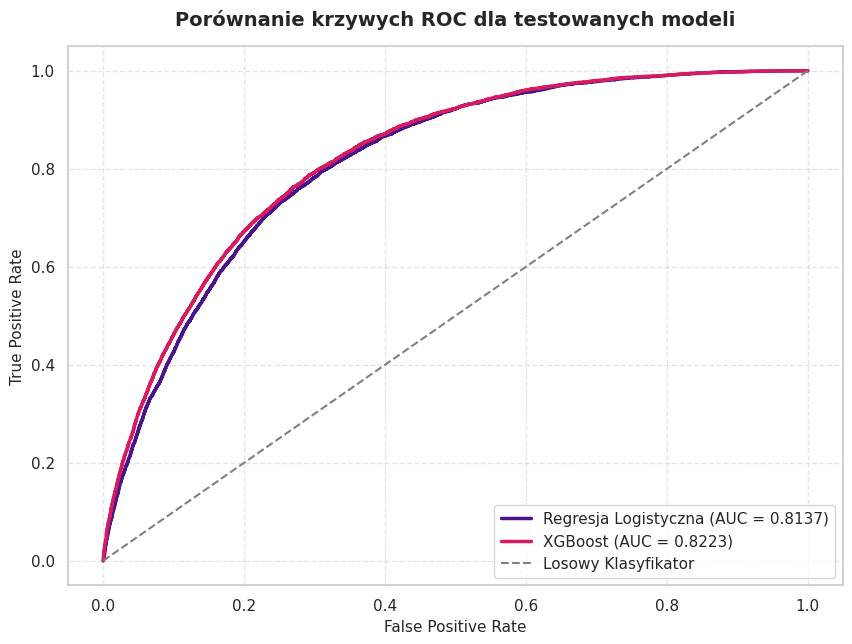

In [17]:
from sklearn.metrics import roc_curve, auc

get_prob_1 = spark_udf(lambda v: float(v[1]), DoubleType())
probs_lr = pred_lr.withColumn("prob_1", get_prob_1("probability")).select("prob_1").toPandas()["prob_1"]
probs_xgb = pred_xgb.withColumn("prob_1", get_prob_1("probability")).select("prob_1").toPandas()["prob_1"]

fpr_lr, tpr_lr, _ = roc_curve(y_true_lr, probs_lr)
auc_lr = auc(fpr_lr, tpr_lr)

fpr_xgb, tpr_xgb, _ = roc_curve(y_true_xgb, probs_xgb)
auc_xgb = auc(fpr_xgb, tpr_xgb)

plt.figure(figsize=(10, 7))
plt.plot(fpr_lr, tpr_lr, color='#4a148c', lw=2.5, label=f'Regresja Logistyczna (AUC = {auc_lr:.4f})')
plt.plot(fpr_xgb, tpr_xgb, color='#d81b60', lw=2.5, label=f'XGBoost (AUC = {auc_xgb:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Losowy Klasyfikator')
plt.title('Porównanie krzywych ROC dla testowanych modeli', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

---

## **9. Wnioski**

* Analizowany zbiór nie zawierał brakujących wartości. Pozwoliło to na pominięcie etapu czyszczenia i bezpośrednie przejście do głębszej eksploracji danych.

* Zidentyfikowano silną dysproporcję w zmiennej docelowej (84,2% pacjentów zdrowych wobec 15,8% pacjentów chorych lub w stanie przedcukrzycowym). Wymusiło to binaryzację zmiennej celu z wykorzystaniem paradygmatu MapReduce oraz zastosowanie class weights podczas treningu, co zapobiega ignorowaniu przez algorytmy klasy mniejszościowej.

* Przeprowadzono ewaluację porównawczą modeli Regresji Logistycznej oraz XGBoost. Wyniki dla obydwu modeli są podobne, jednakże algorytm XGBoost cechuje się lekko wyższą zdolnością predykcyjną (AUC-ROC - 0.8223) w porównaniu do bazowego modelu regresji (AUC-ROC - 0.8137), lepiej radząc sobie ze złożonymi zależnościami w danych medycznych. 

* Otrzymane wyniki pokazują, że opracowany model może mieć realne zastosowanie w przewidywaniu ryzyka cukrzycy. Projekt dobrze radzi sobie z danymi i ma potencjał do dalszego rozwoju, np. przez użycie większych zbiorów danych i dodatkowych cech klinicznych, co mogłoby jeszcze poprawić jakość predykcji.